**Aim:**

To generate images from descriptive text using Stable Diffusion and compare different prompt styles while keeping the seed and generation settings constant.

**Software and Libraries Used:**
1. Python
2. Google Colab
3. PyTorch
4. Hugging Face Diffusers
5. Transformers
6. Matplotlib

2.** Theory**

Stable Diffusion is a generative AI model that creates images from text descriptions.

It works through the following process:
1. User enters a text prompt.
2. The model converts the text into guidance for image generation.
3. It starts with random noise.
4. The denoising process gradually creates an image.
5. The final image is decoded and displayed.

In [2]:


%pip install -q "diffusers>=0.33,<1" "transformers>=4.51,<5" accelerate safetensors


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [3]:


from pathlib import Path
import random
import torch
import matplotlib.pyplot as plt

from IPython.display import display
from diffusers import StableDiffusionPipeline


SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


out = Path("lab_outputs")
out.mkdir(exist_ok=True)

print("Device:", device)
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())


Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Device: cuda
PyTorch Version: 2.14.1+cu130
CUDA Available: True


In [4]:


assert device.type == "cuda", (
    "Select a GPU runtime and rerun setup."
)

repo = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    repo,
    torch_dtype=torch.float16
)

pipe = pipe.to(device)


pipe.enable_attention_slicing()

print("Stable Diffusion loaded successfully!")
print("Model:", repo)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

config.json: 0.00B [00:00, ?B/s]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

... (9 outputs left out)

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Stable Diffusion loaded successfully!
Model: stable-diffusion-v1-5/stable-diffusion-v1-5


In [5]:


prompts = [
    "A small library with a reading table, wide view, watercolor illustration",

    "A small library with a reading table, wide view, pencil sketch"
]

for i, prompt in enumerate(prompts, 1):
    print(f"Prompt {i}:")
    print(prompt)
    print()


Prompt 1:
A small library with a reading table, wide view, watercolor illustration

Prompt 2:
A small library with a reading table, wide view, pencil sketch



  0%|          | 0/25 [00:00<?, ?it/s]

Generated: library_prompt_1_seed_42.png


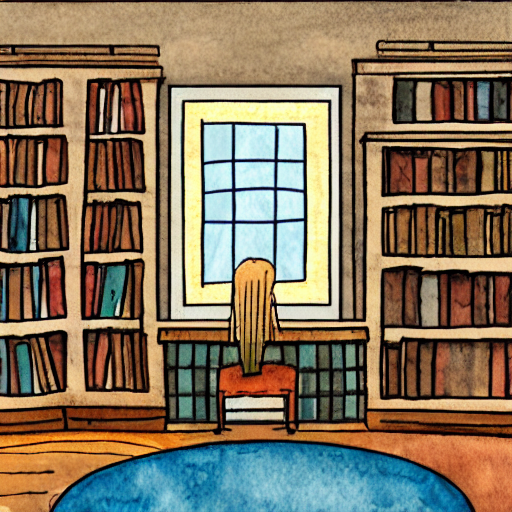

  0%|          | 0/25 [00:00<?, ?it/s]

Generated: library_prompt_1_seed_43.png


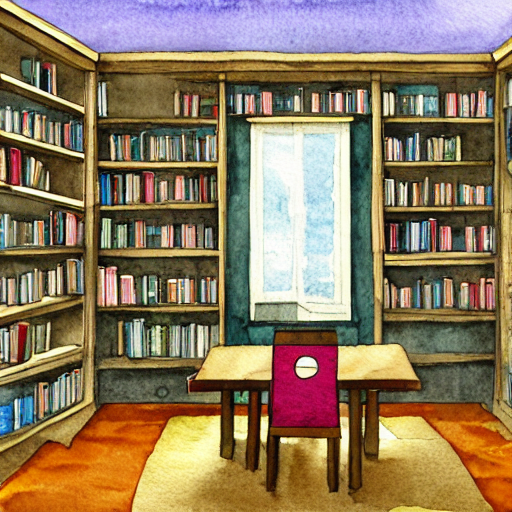

  0%|          | 0/25 [00:00<?, ?it/s]

Generated: library_prompt_2_seed_42.png


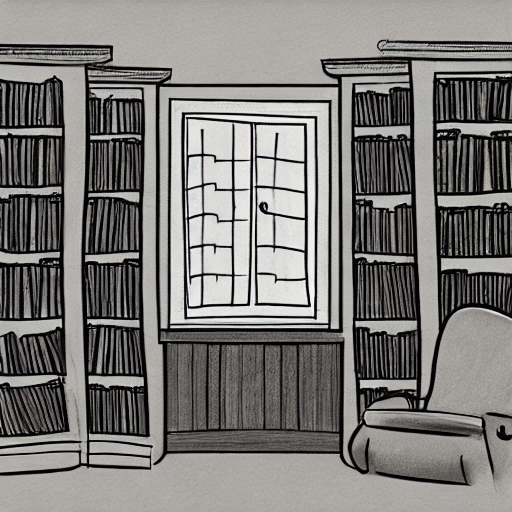

  0%|          | 0/25 [00:00<?, ?it/s]

Generated: library_prompt_2_seed_43.png


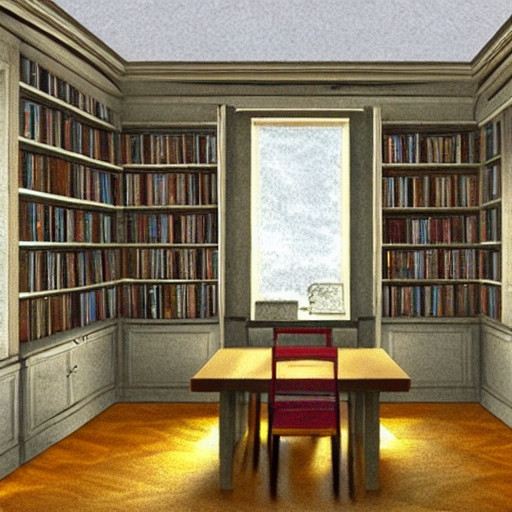

Image generation completed!


In [6]:



for i, prompt in enumerate(prompts, 1):

    for seed in (42, 43):

        rng = torch.Generator(
            device=device
        ).manual_seed(seed)


        result = pipe(
            prompt,
            width=512,
            height=512,
            num_inference_steps=25,
            guidance_scale=7.5,
            generator=rng
        )


        flags = result.nsfw_content_detected

        if flags and flags[0]:
            print("Image flagged. Review the classroom prompt.")
            continue


        image = result.images[0]


        filename = f"library_prompt_{i}_seed_{seed}.png"

        image.save(out / filename)

        print("Generated:", filename)


        display(image)

print("Image generation completed!")
